# Day 107 — Loss Functions in Deep Learning

A **loss function** tells the network how wrong a prediction is. Training means minimizing it with gradient descent.

In this notebook (NumPy and Matplotlib only, no TensorFlow needed) we will:
1. Separate **loss** (one sample) from **cost** (whole batch/dataset, plus regularization)
2. Implement and compare the **regression losses**: MSE, MAE, RMSE, Huber
3. See how each loss reacts to **outliers** (mean vs median, and line fitting)
4. Implement the **classification losses**: binary cross entropy, categorical and sparse categorical cross entropy, hinge
5. Understand **logits and numerical stability**
6. See why **cross entropy beats MSE** for classification (gradients)
7. Try **focal loss** for imbalanced data, and the link to **KL divergence**
8. Use a **sanity check** for the initial loss, and add **L2 regularization** to a cost
9. Optionally cross-check against Keras' built-in losses

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## 1. Loss vs cost

- **Loss** `L(y, ŷ)`: error on a **single** sample
- **Cost** `J`: average loss over a **batch or the whole dataset**, often plus a regularization term:
  `J = (1/n) Σ L(yᵢ, ŷᵢ) + λ · R(w)`

In [4]:
y_true = np.array([3.0, -0.5, 2.0, 7.0])
y_pred = np.array([2.5,  0.0, 2.0, 8.0])

per_sample_squared_loss = (y_true - y_pred) ** 2          # loss for each sample
cost = per_sample_squared_loss.mean()                      # cost = average loss
print("Loss per sample:", per_sample_squared_loss)
print("Cost (mean)    :", cost)

Loss per sample: [0.25 0.25 0.   1.  ]
Cost (mean)    : 0.375


## 2. Regression losses

| Loss | Formula (per sample) |
|---|---|
| MSE | `(y − ŷ)²` |
| MAE | `\|y − ŷ\|` |
| RMSE | `sqrt(mean((y − ŷ)²))` (a cost, not per sample) |
| Huber (δ) | `½e²` if `\|e\| ≤ δ`, else `δ(\|e\| − ½δ)`, with `e = y − ŷ` |

In [5]:
def mse(y, p):   return np.mean((y - p) ** 2)
def mae(y, p):   return np.mean(np.abs(y - p))
def rmse(y, p):  return np.sqrt(mse(y, p))

def huber(y, p, delta=1.0):
    e = y - p
    small = np.abs(e) <= delta
    return np.mean(np.where(small, 0.5 * e ** 2, delta * (np.abs(e) - 0.5 * delta)))

print(f"MSE   = {mse(y_true, y_pred):.4f}")
print(f"MAE   = {mae(y_true, y_pred):.4f}")
print(f"RMSE  = {rmse(y_true, y_pred):.4f}")
print(f"Huber = {huber(y_true, y_pred):.4f}")

MSE   = 0.3750
MAE   = 0.5000
RMSE  = 0.6124
Huber = 0.1875


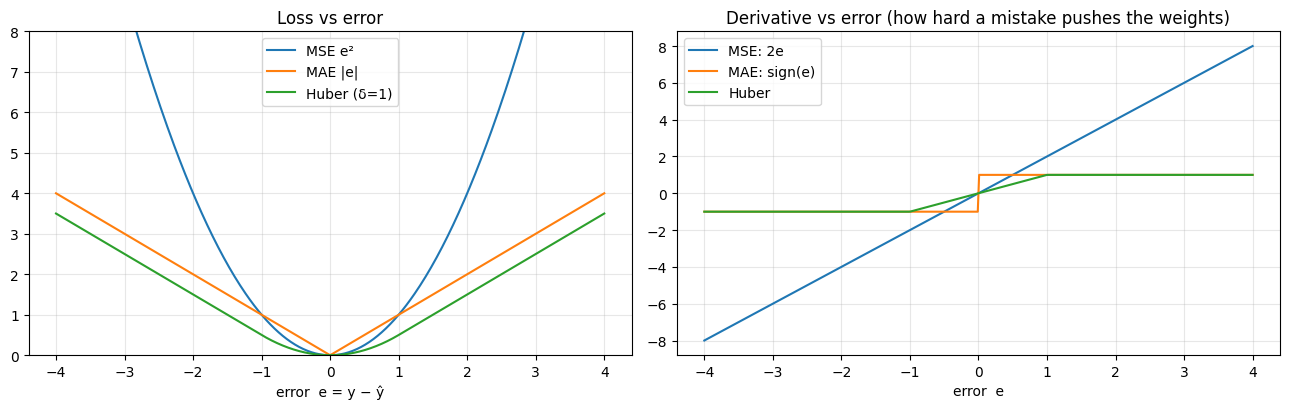

In [6]:
e = np.linspace(-4, 4, 400)
mse_l = e ** 2
mae_l = np.abs(e)
hub_l = np.where(np.abs(e) <= 1, 0.5 * e ** 2, 1.0 * (np.abs(e) - 0.5))

# derivatives with respect to the error e = y - y_hat
mse_g = 2 * e
mae_g = np.sign(e)
hub_g = np.where(np.abs(e) <= 1, e, np.sign(e))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(e, mse_l, label="MSE e²"); axes[0].plot(e, mae_l, label="MAE |e|"); axes[0].plot(e, hub_l, label="Huber (δ=1)")
axes[0].set_ylim(0, 8); axes[0].set_title("Loss vs error"); axes[0].set_xlabel("error  e = y − ŷ"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(e, mse_g, label="MSE: 2e"); axes[1].plot(e, mae_g, label="MAE: sign(e)"); axes[1].plot(e, hub_g, label="Huber")
axes[1].set_title("Derivative vs error (how hard a mistake pushes the weights)"); axes[1].set_xlabel("error  e"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading the plots**
- **MSE** gradient grows with the error, so big mistakes (outliers) dominate learning. It is smooth, so gradient descent behaves well near the optimum.
- **MAE** gradient has constant size, so it is robust to outliers, but it does not shrink near the optimum and is not differentiable at 0.
- **Huber** behaves like MSE for small errors and like MAE for large ones.

## 3. Outliers: mean vs median

The constant `c` that minimizes **MSE** is the **mean**. The constant that minimizes **MAE** is the **median**.

In [7]:
data = np.array([1.0, 2.0, 3.0, 4.0, 100.0])           # one big outlier
candidates = np.linspace(0, 110, 11001)

best_mse = candidates[np.argmin([mse(data, np.full_like(data, c)) for c in candidates])]
best_mae = candidates[np.argmin([mae(data, np.full_like(data, c)) for c in candidates])]
print(f"Best constant for MSE: {best_mse:.2f}   (mean   = {data.mean():.2f})")
print(f"Best constant for MAE: {best_mae:.2f}   (median = {np.median(data):.2f})")

Best constant for MSE: 22.00   (mean   = 22.00)
Best constant for MAE: 3.00   (median = 3.00)


### Fitting a line with different losses

Data from `y = 2x + 1` plus noise, and four large outliers. We fit `y = w·x + b` by gradient descent using each loss.

MSE   : slope =  3.827, intercept = -4.075   (true: slope 2, intercept 1)
MAE   : slope =  1.994, intercept =  1.423   (true: slope 2, intercept 1)
HUBER : slope =  2.026, intercept =  1.467   (true: slope 2, intercept 1)


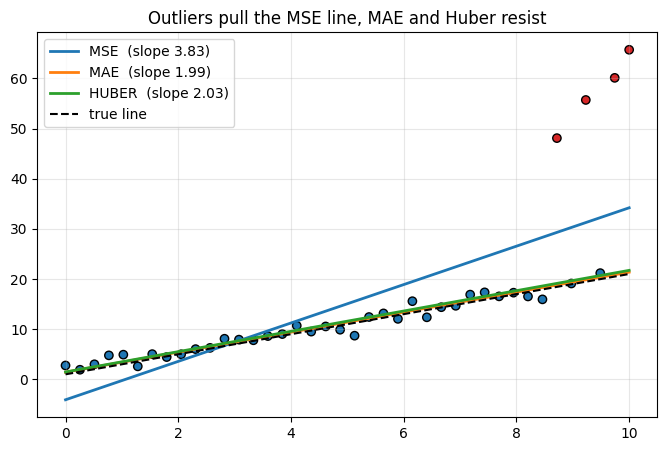

In [8]:
rng = np.random.RandomState(0)
x = np.linspace(0, 10, 40)
y = 2 * x + 1 + rng.randn(40) * 1.0
y[[34, 36, 38, 39]] += np.array([30, 35, 40, 45])          # outliers at large x

def fit_line(x, y, loss="mse", delta=1.0, lr=0.01, steps=40000):
    w, b = 0.0, 0.0
    for t in range(steps):
        p = w * x + b
        e = y - p
        if loss == "mse":    g = -2 * e
        elif loss == "mae":  g = -np.sign(e)
        else:                g = -np.where(np.abs(e) <= delta, e, delta * np.sign(e))
        step = lr / (1 + t / 2000) if loss == "mae" else lr                # MAE needs a decaying step
        w -= step * np.mean(g * x); b -= step * np.mean(g)
    return w, b

fits = {name: fit_line(x, y, name) for name in ["mse", "mae", "huber"]}
for name, (w, b) in fits.items():
    print(f"{name.upper():6s}: slope = {w:6.3f}, intercept = {b:6.3f}   (true: slope 2, intercept 1)")

plt.figure(figsize=(8, 5))
plt.scatter(x, y, c=["tab:red" if i in (34, 36, 38, 39) else "tab:blue" for i in range(40)], edgecolor="k")
xs = np.array([0, 10])
for name, (w, b) in fits.items():
    plt.plot(xs, w * xs + b, label=f"{name.upper()}  (slope {w:.2f})", lw=2)
plt.plot(xs, 2 * xs + 1, "k--", label="true line")
plt.legend(); plt.title("Outliers pull the MSE line, MAE and Huber resist"); plt.grid(alpha=0.3); plt.show()

## 4. Classification losses

### 4.1 Binary cross entropy (BCE)

`BCE = −[ y·log(p) + (1 − y)·log(1 − p) ]` with `p = sigmoid(z)`

Per-sample BCE: [0.1054 0.1054 0.2231 1.204  0.9163]
Mean BCE      : 0.5108


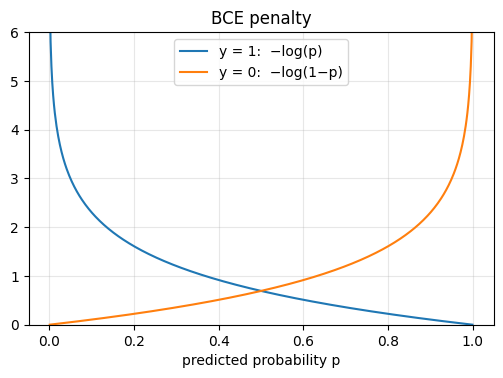

In [9]:
def sigmoid(z): return 1 / (1 + np.exp(-z))

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

y_b = np.array([1, 0, 1, 1, 0])
p_b = np.array([0.9, 0.1, 0.8, 0.3, 0.6])
print("Per-sample BCE:", (-(y_b * np.log(p_b) + (1 - y_b) * np.log(1 - p_b))).round(4))
print("Mean BCE      :", round(bce(y_b, p_b), 4))

pp = np.linspace(0.001, 0.999, 500)
plt.figure(figsize=(6, 3.8))
plt.plot(pp, -np.log(pp), label="y = 1:  −log(p)"); plt.plot(pp, -np.log(1 - pp), label="y = 0:  −log(1−p)")
plt.ylim(0, 6); plt.xlabel("predicted probability p"); plt.grid(alpha=0.3); plt.legend(); plt.title("BCE penalty"); plt.show()

### 4.2 Categorical cross entropy (CCE) and sparse categorical cross entropy (SCCE)

For `K` classes with softmax probabilities `p` and a one-hot target `y`: `CCE = −Σₖ yₖ log(pₖ) = −log(p_true class)`.

**Sparse** version: the label is an **integer** class index instead of a one-hot vector. The result is identical.

In [10]:
def softmax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def categorical_ce(Y_onehot, P, eps=1e-12):
    return -np.mean(np.sum(Y_onehot * np.log(np.clip(P, eps, 1)), axis=1))

def sparse_categorical_ce(y_int, P, eps=1e-12):
    return -np.mean(np.log(np.clip(P[np.arange(len(y_int)), y_int], eps, 1)))

logits = np.array([[2.0, 1.0, 0.1],
                   [0.5, 2.5, 0.3],
                   [1.2, 0.2, 3.0]])
P = softmax(logits)
y_int = np.array([0, 1, 2])
Y_onehot = np.eye(3)[y_int]

print("Probabilities:\n", P.round(3))
print("Categorical CE (one-hot labels)  :", round(categorical_ce(Y_onehot, P), 5))
print("Sparse categorical CE (int labels):", round(sparse_categorical_ce(y_int, P), 5))
print("Identical:", np.isclose(categorical_ce(Y_onehot, P), sparse_categorical_ce(y_int, P)))

Probabilities:
 [[0.659 0.242 0.099]
 [0.109 0.802 0.089]
 [0.135 0.05  0.816]]
Categorical CE (one-hot labels)  : 0.28031
Sparse categorical CE (int labels): 0.28031
Identical: True


### 4.3 Hinge loss

For labels `t ∈ {−1, +1}` and score `s`: `max(0, 1 − t·s)` (used by SVMs). Compare with Day 99.

In [11]:
def hinge(t, s): return np.mean(np.maximum(0, 1 - t * s))
def squared_hinge(t, s): return np.mean(np.maximum(0, 1 - t * s) ** 2)

t = np.array([1, 1, -1, -1]); s = np.array([2.0, 0.3, -0.5, 0.8])
print("Per-sample hinge:", np.maximum(0, 1 - t * s))
print("Mean hinge      :", hinge(t, s), "| mean squared hinge:", squared_hinge(t, s))

Per-sample hinge: [0.  0.7 0.5 1.8]
Mean hinge      : 0.75 | mean squared hinge: 0.9950000000000001


## 5. Logits and numerical stability

Computing `softmax` first and then `log` can underflow or overflow for extreme logits. The stable way works on the **logits** directly (the `from_logits=True` idea in Keras) using the **log-sum-exp trick**:

`log softmax(z)ₖ = zₖ − log Σⱼ e^{zⱼ}`

In [12]:
def ce_from_logits(y_int, Z):
    Zs = Z - Z.max(axis=1, keepdims=True)                       # shift for stability
    log_probs = Zs - np.log(np.exp(Zs).sum(axis=1, keepdims=True))
    return -np.mean(log_probs[np.arange(len(y_int)), y_int])

extreme = np.array([[1000.0, 0.0, -1000.0]])
y_ext = np.array([2])                                           # the model is extremely wrong

with np.errstate(all="ignore"):
    naive = -np.log(np.exp(extreme) / np.exp(extreme).sum(axis=1, keepdims=True))[0, 2]
print("Naive  softmax -> log:", naive, "(broken: exp overflows, so this is not a usable number)")
print("Stable from-logits CE:", ce_from_logits(y_ext, extreme), "(correct: the loss is 2000)")
print("Clipped probabilities (eps=1e-12) would cap the loss at", round(-np.log(1e-12), 2), "and hide how wrong the model is")

Naive  softmax -> log: inf (broken: exp overflows, so this is not a usable number)
Stable from-logits CE: 2000.0 (correct: the loss is 2000)
Clipped probabilities (eps=1e-12) would cap the loss at 27.63 and hide how wrong the model is


## 6. Why cross entropy beats MSE for classification

With a sigmoid output `p = σ(z)`, the gradient of the loss with respect to `z` is:
- **BCE:** `p − y`
- **MSE:** `(p − y) · p · (1 − p)` (the extra `p(1−p)` factor vanishes when the sigmoid saturates)

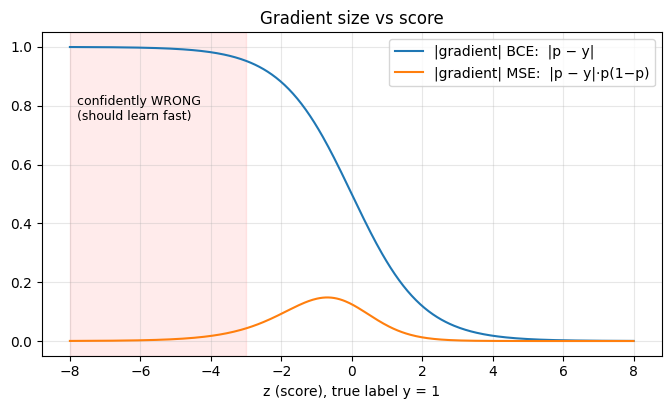

At z = -6 (very wrong): BCE gradient = 0.9975, MSE gradient = 0.002473


In [13]:
z = np.linspace(-8, 8, 400)
p = sigmoid(z)
y_one = 1.0                                   # true class is 1

grad_bce = p - y_one
grad_mse = (p - y_one) * p * (1 - p)

plt.figure(figsize=(8, 4.2))
plt.plot(z, np.abs(grad_bce), label="|gradient| BCE:  |p − y|")
plt.plot(z, np.abs(grad_mse), label="|gradient| MSE:  |p − y|·p(1−p)")
plt.axvspan(-8, -3, color="red", alpha=0.08); plt.text(-7.8, 0.75, "confidently WRONG\n(should learn fast)", fontsize=9)
plt.xlabel("z (score), true label y = 1"); plt.legend(); plt.grid(alpha=0.3); plt.title("Gradient size vs score"); plt.show()

k = np.argmin(np.abs(z + 6))
print(f"At z = -6 (very wrong): BCE gradient = {abs(grad_bce[k]):.4f}, MSE gradient = {abs(grad_mse[k]):.6f}")

## 7. Focal loss for imbalanced classification

`FL = −α · (1 − pₜ)^γ · log(pₜ)`, where `pₜ` is the probability given to the true class.
The factor `(1 − pₜ)^γ` **down-weights easy examples** so training focuses on hard ones.

In [14]:
def focal_loss_single(p_t, gamma=2.0, alpha=1.0):
    return -alpha * (1 - p_t) ** gamma * np.log(p_t)

print(f"{'p_t':>5} | {'cross entropy':>13} | {'focal (γ=2)':>11} | {'ratio':>7}")
for p_t in [0.99, 0.9, 0.7, 0.5, 0.2, 0.1]:
    ce = -np.log(p_t); fl = focal_loss_single(p_t)
    print(f"{p_t:5.2f} | {ce:13.4f} | {fl:11.4f} | {fl / ce:7.3f}")
print("Easy examples (high p_t) are down-weighted heavily, hard ones keep most of their loss.")

  p_t | cross entropy | focal (γ=2) |   ratio
 0.99 |        0.0101 |      0.0000 |   0.000
 0.90 |        0.1054 |      0.0011 |   0.010
 0.70 |        0.3567 |      0.0321 |   0.090
 0.50 |        0.6931 |      0.1733 |   0.250
 0.20 |        1.6094 |      1.0300 |   0.640
 0.10 |        2.3026 |      1.8651 |   0.810
Easy examples (high p_t) are down-weighted heavily, hard ones keep most of their loss.


## 8. Cross entropy and KL divergence

`CE(p, q) = H(p) + KL(p || q)`: cross entropy equals the entropy of the true distribution plus the KL divergence from the prediction.
For one-hot targets `H(p) = 0`, so **minimizing cross entropy = minimizing KL divergence** to the true distribution.

In [15]:
p_true = np.array([0.7, 0.2, 0.1])
q_pred = np.array([0.5, 0.3, 0.2])

entropy = -np.sum(p_true * np.log(p_true))
cross_entropy = -np.sum(p_true * np.log(q_pred))
kl = np.sum(p_true * np.log(p_true / q_pred))
print(f"H(p) = {entropy:.4f} | CE(p, q) = {cross_entropy:.4f} | KL(p||q) = {kl:.4f}")
print("CE = H + KL :", np.isclose(cross_entropy, entropy + kl))

one_hot = np.array([1.0, 0.0, 0.0])
ce_oh = -np.sum(one_hot * np.log(q_pred))
print(f"One-hot target: CE = {ce_oh:.4f} = -log(q_true) = {-np.log(q_pred[0]):.4f}")

H(p) = 0.8018 | CE(p, q) = 0.8869 | KL(p||q) = 0.0851
CE = H + KL : True
One-hot target: CE = 0.6931 = -log(q_true) = 0.6931


## 9. Sanity check: the expected initial loss

A network that has not learned anything outputs roughly uniform probabilities, so for `K` classes the starting cross entropy should be about `ln(K)`.
If your first epoch shows something very different, there is probably a bug.

In [16]:
rng = np.random.RandomState(0)
for K in [2, 10, 100]:
    X = rng.randn(2000, 20)
    W = rng.randn(20, K) * 0.01                                    # small random weights
    P = softmax(X @ W)
    y_rand = rng.randint(0, K, size=2000)
    print(f"K = {K:3d}: initial CE = {sparse_categorical_ce(y_rand, P):.4f} | ln(K) = {np.log(K):.4f}")

K =   2: initial CE = 0.6936 | ln(K) = 0.6931
K =  10: initial CE = 2.3032 | ln(K) = 2.3026
K = 100: initial CE = 4.6045 | ln(K) = 4.6052


## 10. Cost with regularization

`J = mean loss + λ · ||w||²` (L2). The penalty keeps weights small and reduces overfitting.
Example: polynomial regression with many features, with and without L2 (ridge).

In [17]:
rng = np.random.RandomState(1)
x_tr = np.linspace(-1, 1, 15);           y_tr = np.sin(3 * x_tr) + rng.randn(15) * 0.2
x_te = np.linspace(-1, 1, 200);          y_te = np.sin(3 * x_te)

def poly(x, deg): return np.vander(x, deg + 1, increasing=True)

def fit_ridge(x, y, deg, lam):
    A = poly(x, deg)
    if lam == 0:
        return np.linalg.lstsq(A, y, rcond=None)[0]                   # plain least squares (no penalty)
    I = np.eye(A.shape[1]); I[0, 0] = 0                              # do not penalize the bias
    return np.linalg.solve(A.T @ A + lam * len(x) * I, A.T @ y)

print(f"{'lambda':>8} | {'train MSE':>9} | {'test MSE':>8} | {'||w||²':>10}")
for lam in [0.0, 1e-4, 1e-2, 1e-1]:
    w = fit_ridge(x_tr, y_tr, 12, lam)
    print(f"{lam:8.4f} | {mse(y_tr, poly(x_tr, 12) @ w):9.4f} | {mse(y_te, poly(x_te, 12) @ w):8.4f} | {np.sum(w[1:] ** 2):10.2f}")

  lambda | train MSE | test MSE |     ||w||²
  0.0000 |    0.0231 |   0.6848 | 17697351.91
  0.0001 |    0.0418 |   0.0093 |      29.97
  0.0100 |    0.0766 |   0.0343 |       4.35
  0.1000 |    0.1869 |   0.1368 |       0.99


## 11. Which loss should I use?

In [18]:
guide = [
    ("Regression (normal errors)",        "Linear (no activation)", "MSE (+ MAE as a metric)"),
    ("Regression with outliers",           "Linear",                 "MAE or Huber"),
    ("Binary classification",              "Sigmoid (1 node)",       "Binary cross entropy"),
    ("Multi-class, one-hot labels",        "Softmax (K nodes)",      "Categorical cross entropy"),
    ("Multi-class, integer labels",        "Softmax (K nodes)",      "Sparse categorical cross entropy"),
    ("Multi-label (several can be true)",  "Sigmoid (K nodes)",      "Binary cross entropy per label"),
    ("Imbalanced classes",                 "Sigmoid / Softmax",      "Weighted CE or focal loss"),
    ("Margin-based (SVM style)",           "Raw score",              "Hinge loss"),
]
print(f"{'Task':36s} | {'Output layer':24s} | Loss")
print("-" * 100)
for task, out, loss in guide:
    print(f"{task:36s} | {out:24s} | {loss}")

Task                                 | Output layer             | Loss
----------------------------------------------------------------------------------------------------
Regression (normal errors)           | Linear (no activation)   | MSE (+ MAE as a metric)
Regression with outliers             | Linear                   | MAE or Huber
Binary classification                | Sigmoid (1 node)         | Binary cross entropy
Multi-class, one-hot labels          | Softmax (K nodes)        | Categorical cross entropy
Multi-class, integer labels          | Softmax (K nodes)        | Sparse categorical cross entropy
Multi-label (several can be true)    | Sigmoid (K nodes)        | Binary cross entropy per label
Imbalanced classes                   | Sigmoid / Softmax        | Weighted CE or focal loss
Margin-based (SVM style)             | Raw score                | Hinge loss


## 12. Optional: cross-check with Keras' built-in losses

Runs only if TensorFlow is installed. The values should match the NumPy versions above.

In [24]:
try:
    from tensorflow import keras
    L = keras.losses
    P = softmax(logits)
    print("MSE   :", float(L.MeanSquaredError()(y_true, y_pred)), "| ours:", round(mse(y_true, y_pred), 6))
    print("MAE   :", float(L.MeanAbsoluteError()(y_true, y_pred)), "| ours:", round(mae(y_true, y_pred), 6))
    print("Huber :", float(L.Huber(delta=1.0)(y_true, y_pred)), "| ours:", round(huber(y_true, y_pred), 6))
    print("BCE   :", float(L.BinaryCrossentropy()(y_b.astype("float32"), p_b.astype("float32"))), "| ours:", round(bce(y_b, p_b), 6))
    print("CCE   :", float(L.CategoricalCrossentropy()(Y_onehot, P)), "| ours:", round(categorical_ce(Y_onehot, P), 6))
    print("SCCE  :", float(L.SparseCategoricalCrossentropy()(y_int, P)), "| ours:", round(sparse_categorical_ce(y_int, P), 6))
    print("SCCE from logits:", float(L.SparseCategoricalCrossentropy(from_logits=True)(y_int, logits)), "| ours:", round(ce_from_logits(y_int, logits), 6))
except ImportError:
    print("TensorFlow is not installed, skipping the Keras cross-check.")

MSE   : 0.375 | ours: 0.375
MAE   : 0.5 | ours: 0.5
Huber : 0.1875 | ours: 0.1875
BCE   : 0.5108256340026855 | ours: 0.510826
CCE   : 0.2803083658218384 | ours: 0.280308
SCCE  : 0.28030842542648315 | ours: 0.280308
SCCE from logits: 0.28030839562416077 | ours: 0.280308


## Summary

| Problem | Output layer | Loss |
|---|---|---|
| Regression | Linear | MSE / MAE / Huber |
| Binary | Sigmoid | Binary cross entropy |
| Multi-class | Softmax | (Sparse) categorical cross entropy |
| Multi-label | Sigmoid per label | Binary cross entropy per label |
| Imbalanced | Sigmoid / Softmax | Weighted or focal loss |

- **Loss** is per sample, **cost** is the average (plus regularization)
- MSE is smooth but outlier-sensitive; MAE is robust but has a constant gradient; Huber combines both
- Cross entropy gives the clean gradient `p − y` and avoids the vanishing-gradient problem of MSE with sigmoid
- Use **logits-based** cross entropy for numerical stability
- Initial loss should be near `ln(K)`

## Practice exercises

1. Change `delta` in the Huber loss (0.1, 1, 10) and fit the line again. What happens as `delta` grows or shrinks?
2. Implement **log-cosh** loss (`log(cosh(e))`) and add it to the loss-vs-error plot.
3. Implement **weighted binary cross entropy** (weight for the positive class) and test on data with 5% positives.
4. Add **label smoothing** (target 0.9 / 0.1 instead of 1 / 0) to the cross entropy and see how the loss changes.
5. Plot the focal loss for `γ = 0, 1, 2, 5` against `pₜ`.
6. Check the initial-loss rule on a real Keras model: build a randomly initialized MNIST classifier and compare its first-batch loss with `ln(10) ≈ 2.303`.